# SiN Grating Coupler with an a-Si Overlay (Step 4)

Steps 2 and 3 found that the directionality of a single-etch SiN grating stays near
0.73 however the meta-atoms are arranged in the plane: all of them scatter at the same
height, so no in-plane arrangement can move power from the downward beam to the upward
one. Breaking the **vertical** symmetry is the other route. This notebook studies a
grating etched into a high-index **amorphous-silicon (a-Si) overlay** on top of the SiN
waveguide, following the design of Fraser et al. [1].

The stack is Si substrate / 4.5 µm BOX / 400 nm SiN / 50 nm oxide buffer / 220 nm a-Si /
air, at 1.31 µm. The a-Si (n = 3.52) is fully etched into teeth over the grating only;
the input waveguide is bare SiN. Along the propagation direction each period holds one
a-Si tooth and one trench.

**Model:** Meep 2D x-z cross-section with bulk indices at 1.31 µm, non-dispersive,
y-invariant (an infinitely wide, straight grating). Physical TE (E along y) is Meep's
`mp.TM` parity in this rotated-axis convention; physical TM is `mp.TE`. η is the same
reciprocity overlap with a tilted Gaussian SMF-28 mode as in Steps 1–3, normalized by
the incident guided power, here extended to TM. Code:
`src/pic_toolkit/meep_sim/asi_grating.py`.

## Contents
0. Setup
1. The design
2. Input waveguide modes (TE and TM)
3. Mesh convergence
4. Coupling at the reference resolution
5. What the buffer controls
6. TM with the same grating
7. Summary
8. References

**Do not use "Run All."** The finest runs take about an hour each on one core. Results
are cached in `meta/data/step4_asi_overlay/` and reloaded on a re-run.

## 0. Setup

In [1]:
# Imports, plotting style and the cache folder.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from pic_toolkit import style
from pic_toolkit.meep_sim import asi_grating as ag
from pic_toolkit.meep_sim import sin_grating as sg

style.apply_style()
DATA = Path.cwd().parent / "data" / "step4_asi_overlay"
print({k: ag.DEFAULT[k] for k in ("box_um", "core_um", "buf_um", "asi_um", "period_um", "duty", "n_periods",
                                  "fiber_angle_deg", "mfd_um", "wl0_um")})

{'box_um': 4.5, 'core_um': 0.4, 'buf_um': 0.05, 'asi_um': 0.22, 'period_um': 0.7, 'duty': 0.28, 'n_periods': 31, 'fiber_angle_deg': -4.0, 'mfd_um': 9.2, 'wl0_um': 1.31}


## 1. The design

| Layer / parameter | Value |
|---|---|
| substrate | Si (n = 3.5) |
| BOX | 4.5 µm, n = 1.4467 |
| SiN core | 400 nm, n = 2.0017 |
| oxide buffer | 50 nm, n = 1.4502 |
| a-Si overlay | 220 nm, n = 3.5187, fully etched, over the grating only |
| superstrate | air |
| period / duty cycle | 700 nm / 28 % (a-Si tooth fraction) |
| periods | 31 (21.7 µm) |
| fiber | SMF-28, MFD 9.2 µm, tilted −4° (backward emission) |
| wavelength | 1.31 µm, TE |

The geometry and indices are those of the uniform design in [1]; the 4.5 µm BOX is a
standard SiN-platform thickness, the same class as the BOX chosen in Step 1.

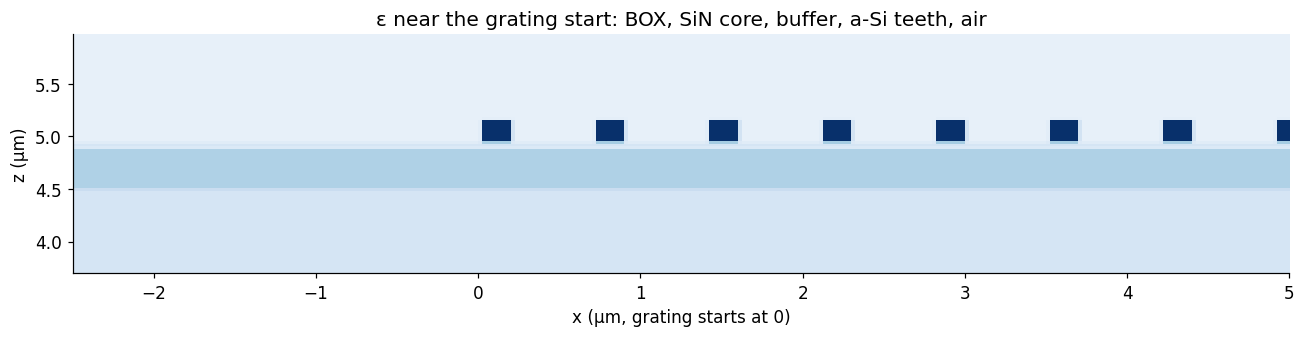

In [2]:
# Permittivity of the simulated cross-section around the start of the grating (from the res-160 run of Section 3).
r160 = sg.cached(DATA / "uniform_TE_res160.pkl", lambda: ag.run_forward({"resolution": 160}, field_map=True))
d = r160["dom"]
ext = [d["x_left"], d["x_right"], d["z_sub0"], d["z_top"]]
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.imshow(r160["eps_map"].T, origin="lower", cmap=style.CMAP_PERMITTIVITY_BASELINE, extent=ext, aspect="auto",
          interpolation="nearest")
ax.set(xlim=(-2.5, 5.0), ylim=(d["z_box1"] - 0.8, d["z_asi1"] + 0.8), xlabel="x (µm, grating starts at 0)",
       ylabel="z (µm)", title="ε near the grating start: BOX, SiN core, buffer, a-Si teeth, air")
ax.grid(False)
fig.tight_layout()
plt.show()

## 2. Input waveguide modes (TE and TM)

The 400 nm SiN waveguide carries both a TE and a TM fundamental mode at 1.31 µm. Their
effective indices from an exact transfer-matrix solution are compared with Meep's
eigensolver on the FDTD grid (source span clear of the Si substrate, as in Step 1). TE is
the higher-index mode; the TE/TM index difference (birefringence) is what puts the two
polarizations at different fiber angles for one grating period (Section 6).

In [3]:
LAYERS = [(ag.DEFAULT["n_core"], 0.40), (ag.DEFAULT["n_buf"], 0.05)]   # input guide: SiN + buffer, air above
n_tmm = {pol: ag.slab_neff_tmm(LAYERS, ag.DEFAULT["n_box"], 1.0, 1.31, pol) for pol in ("TE", "TM")}
modes = sg.cached(DATA / "input_modes.pkl", lambda: {(pol, res): ag.slab_neff_meep({"resolution": res}, pol)
                                                     for pol in ("TE", "TM") for res in (40, 80, 160)})
for pol in ("TE", "TM"):
    meep = ", ".join(f"res {res}: {modes[(pol, res)]:.5f} ({100 * (modes[(pol, res)] / n_tmm[pol] - 1):+.2f}%)"
                     for res in (40, 80, 160))
    print(f"{pol}: TMM {n_tmm[pol]:.5f}; Meep {meep}")
assert n_tmm["TE"] > n_tmm["TM"] and abs(modes[("TE", 160)] / n_tmm["TE"] - 1) < 0.003
print(f"birefringence n_TE - n_TM = {n_tmm['TE'] - n_tmm['TM']:.4f}")

TE: TMM 1.77422; Meep res 40: 1.77152 (-0.15%), res 80: 1.76386 (-0.58%), res 160: 1.77358 (-0.04%)
TM: TMM 1.64999; Meep res 40: 1.63786 (-0.74%), res 80: 1.64210 (-0.48%), res 160: 1.64684 (-0.19%)
birefringence n_TE - n_TM = 0.1242


## 3. Mesh convergence

The mode indices above are not monotonic in resolution (TE: −0.15 %, −0.58 %, −0.04 % at
res 40, 80, 160): the error depends on where the SiN, buffer and a-Si interfaces fall
relative to the grid cells, which changes irregularly with resolution. All values lie
within 0.8 % of the transfer-matrix result, and res 160 agrees to 0.2 %.

The a-Si overlay is the finest and highest-index feature: 220 nm at n = 3.52, i.e. about
0.37 µm per wavelength inside it. The grating is therefore run from res 40 (25 nm cells)
to res 160 (6.25 nm cells) with Meep `Block`s and subpixel averaging. As in Step 1, the
`Block` representation scatters by a few tenths of a dB between neighbouring
resolutions (the averaging error at the tooth corners varies erratically with the grid),
so the trend over the finest resolutions sets the numerical uncertainty.

> **STOP -- the next cell runs the resolution sweep (about two hours on a first run).**

 res  eta (dB)     up   down   dir.  overlap      R      T    wall
  40     -1.82  0.867  0.095   0.90     0.76  0.009  0.032     51s
  60     -2.42  0.846  0.092   0.90     0.68  0.004  0.055    153s
  80     -2.03  0.876  0.072   0.92     0.71  0.006  0.041    365s
 100     -1.63  0.893  0.066   0.93     0.77  0.013  0.023    814s
 120     -1.92  0.875  0.075   0.92     0.73  0.008  0.036   1282s
 160     -1.66  0.889  0.069   0.93     0.77  0.013  0.024   5018s


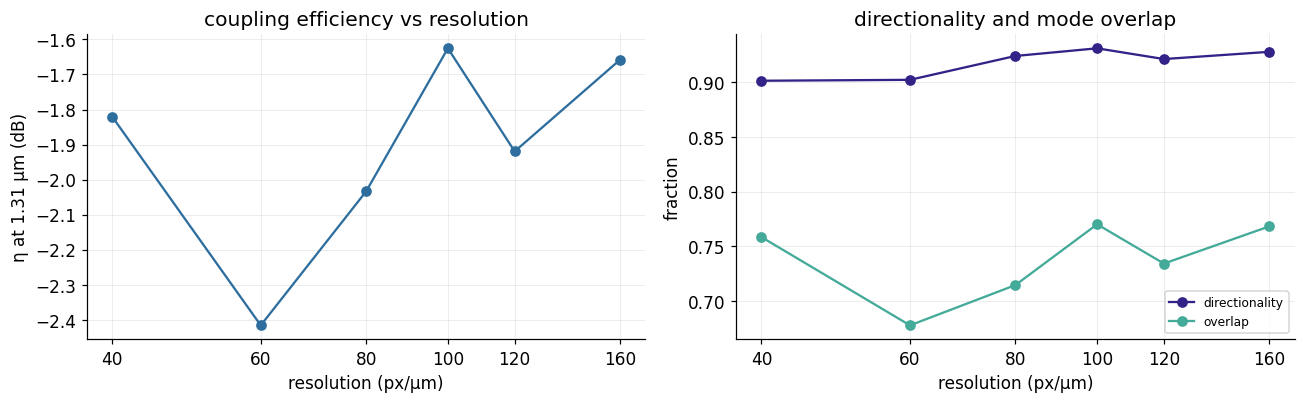

res 100-160: eta -1.92 to -1.63 dB (spread 0.29 dB)


In [4]:
RES = [40, 60, 80, 100, 120, 160]
runs = {res: (r160 if res == 160 else sg.cached(DATA / f"uniform_TE_res{res}.pkl", lambda: ag.run_forward({"resolution": res})))
        for res in RES}
S = {res: ag.summary(r) for res, r in runs.items()}
print(f"{'res':>4} {'eta (dB)':>9} {'up':>6} {'down':>6} {'dir.':>6} {'overlap':>8} {'R':>6} {'T':>6} {'wall':>7}")
for res, s in S.items():
    print(f"{res:>4} {s['eta_db']:>9.2f} {s['up']:>6.3f} {s['down']:>6.3f} {s['directionality']:>6.2f} {s['overlap']:>8.2f} "
          f"{s['R']:>6.3f} {s['T']:>6.3f} {s['wall_s']:>6.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(RES, [S[r]["eta_db"] for r in RES], "o-", color=style.COLOR_STEEL)
axes[0].set(ylabel="η at 1.31 µm (dB)", title="coupling efficiency vs resolution")
for k, c in (("directionality", style.COLOR_CYCLE[0]), ("overlap", style.COLOR_CYCLE[2])):
    axes[1].plot(RES, [S[r][k] for r in RES], "o-", color=c, label=k)
axes[1].set(ylabel="fraction", title="directionality and mode overlap")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set(xscale="log", xlabel="resolution (px/µm)")
    ax.set_xticks(RES, [str(r) for r in RES])
    ax.minorticks_off()
fig.tight_layout()
plt.show()
fine = [S[r]["eta_db"] for r in RES if r >= 100]
print(f"res 100-160: eta {min(fine):.2f} to {max(fine):.2f} dB (spread {max(fine) - min(fine):.2f} dB)")

## 4. Coupling at the reference resolution

Res 160 is the reference, with the res ≥ 100 spread from Section 3 as the numerical
uncertainty. The fiber position is optimized at 1.31 µm and held fixed across the band.

eta -1.66 dB; up 0.889, down 0.069, R 0.013, T 0.024; directionality 0.93, mode overlap 0.77; 1-dB / 3-dB bandwidth 38 / 71 nm


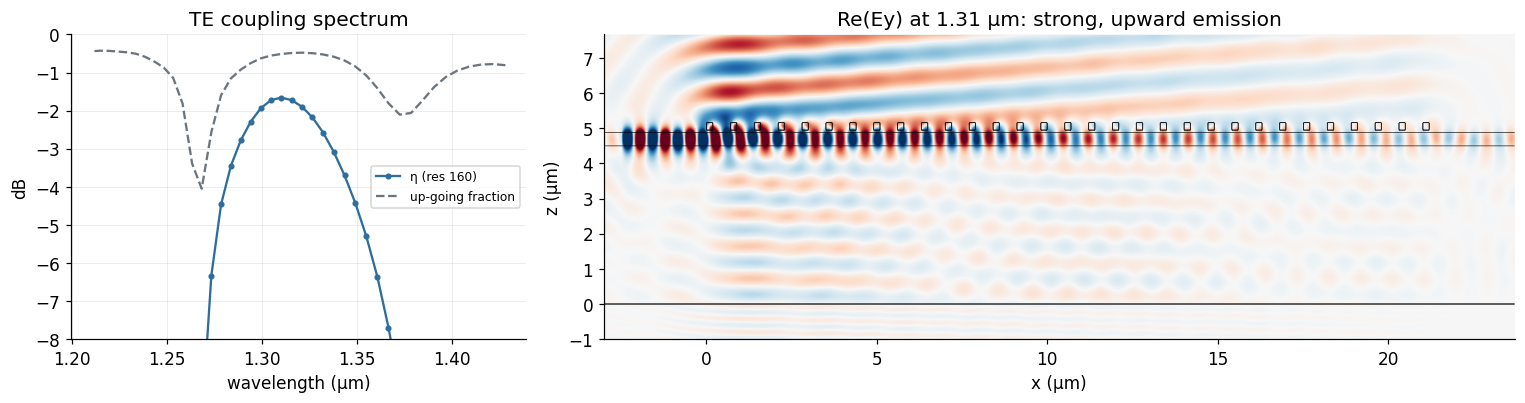

In [5]:
s = S[160]
print(f"eta {s['eta_db']:.2f} dB; up {s['up']:.3f}, down {s['down']:.3f}, R {s['R']:.3f}, T {s['T']:.3f}; "
      f"directionality {s['directionality']:.2f}, mode overlap {s['overlap']:.2f}; "
      f"1-dB / 3-dB bandwidth {s['bw1_nm']:.0f} / {s['bw3_nm']:.0f} nm")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 2]})
wl = r160["wl"]
axes[0].plot(wl, 10 * np.log10(s["spec"]), "o-", ms=3, color=style.COLOR_STEEL, label="η (res 160)")
axes[0].plot(wl, 10 * np.log10(r160["up"]), "--", color=style.COLOR_REFERENCE, label="up-going fraction")
axes[0].set(xlabel="wavelength (µm)", ylabel="dB", ylim=(-8, 0), title="TE coupling spectrum")
axes[0].legend(fontsize=8)
f = np.real(r160["field_map"]).T
v = np.abs(f).max() * 0.4
axes[1].imshow(f, origin="lower", cmap=style.CMAP_FIELD, vmin=-v, vmax=v, extent=ext, aspect="auto")
axes[1].contour(np.linspace(ext[0], ext[1], r160["eps_map"].shape[0]), np.linspace(ext[2], ext[3], r160["eps_map"].shape[1]),
                r160["eps_map"].T, levels=[3.0, 7.0], colors="k", linewidths=0.4)
axes[1].set(xlabel="x (µm)", ylabel="z (µm)", title="Re(Ey) at 1.31 µm: strong, upward emission")
axes[1].grid(False)
fig.tight_layout()
plt.show()

The overlay grating radiates almost entirely upward: directionality 0.93, against 0.73
for the single-etch SiN gratings of Steps 2–3. The coupling efficiency and directionality
agree with those reported for this design in [1] (−1.7 dB, 93 %).

## 5. What the buffer controls

The oxide buffer between SiN and a-Si could act in two ways: through the phase of the
light reflected back up from the BOX/substrate interface, which would show up as a
change of directionality, or through how strongly the a-Si teeth couple to the guided
SiN mode, which would show up as a change of the power passing the grating unscattered.
The buffer alone is swept at res 100 (inside the convergence band).

> **STOP -- the next cell runs six buffer thicknesses (over an hour on a first run).**

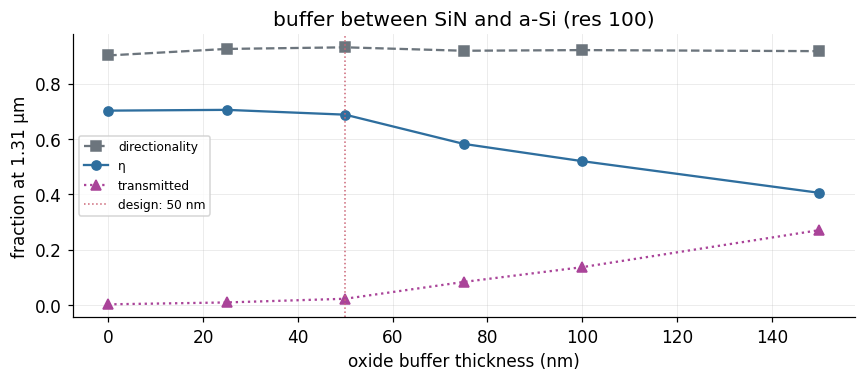

buffer     0 nm: eta  -1.53 dB, directionality 0.90, overlap 0.81, T 0.003
buffer    25 nm: eta  -1.52 dB, directionality 0.93, overlap 0.79, T 0.010
buffer    50 nm: eta  -1.63 dB, directionality 0.93, overlap 0.77, T 0.023
buffer    75 nm: eta  -2.35 dB, directionality 0.92, overlap 0.70, T 0.084
buffer   100 nm: eta  -2.84 dB, directionality 0.92, overlap 0.66, T 0.137
buffer   150 nm: eta  -3.92 dB, directionality 0.92, overlap 0.61, T 0.271


In [6]:
BUF = [0.0, 0.025, 0.05, 0.075, 0.10, 0.15]
buf = {b: ag.summary(sg.cached(DATA / f"buffer_{int(b * 1e3):03d}nm_res100.pkl",
                               lambda: ag.run_forward({"resolution": 100, "buf_um": b}))) for b in BUF}
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot([1e3 * b for b in BUF], [buf[b]["directionality"] for b in BUF], "s--", color=style.COLOR_REFERENCE,
        label="directionality")
ax.plot([1e3 * b for b in BUF], [buf[b]["eta"] for b in BUF], "o-", color=style.COLOR_STEEL, label="η")
ax.plot([1e3 * b for b in BUF], [buf[b]["T"] for b in BUF], "^:", color=style.COLOR_CYCLE[5], label="transmitted")
ax.axvline(50, color=style.COLOR_ROSE, lw=1, ls=":", label="design: 50 nm")
ax.set(xlabel="oxide buffer thickness (nm)", ylabel="fraction at 1.31 µm", title="buffer between SiN and a-Si (res 100)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for b in BUF:
    print(f"buffer {1e3 * b:5.0f} nm: eta {buf[b]['eta_db']:6.2f} dB, directionality {buf[b]['directionality']:.2f}, "
          f"overlap {buf[b]['overlap']:.2f}, T {buf[b]['T']:.3f}")

**Reading the sweep.** Directionality stays at 0.90–0.93 for every buffer thickness: with
the BOX fixed at 4.5 µm, the substrate reflection's phase is set by the BOX, not by the
buffer. What the buffer controls is the **grating strength**: the a-Si teeth sit in the
evanescent tail of the SiN mode, so a thicker buffer couples them more weakly.
Transmission past the 31 periods rises from 0.3 % (no buffer) to 27 % (150 nm), the
emitted beam lengthens and the mode overlap falls, and η drops from −1.5 dB to −3.9 dB.
The 50 nm design value lies on the flat top of this curve.

## 6. TM with the same grating

The SiN guide also carries a TM mode (Section 2), with a lower effective index. The same
grating then phase-matches TM to a different fiber angle and scatters it less. TM
coupling is computed at the TE design angle (−4°) and at TM's own best angle, with the
fiber position re-optimized at each angle.

> **STOP -- the next cell runs TM at res 100 and res 160 (about an hour on a first run).**

TM res 100: at -4 deg -15.12 dB; best -11.0 deg -> -6.62 dB; up 0.371, down 0.172, directionality 0.68, T 0.447


TM res 160: at -4 deg -14.67 dB; best -11.0 deg -> -6.43 dB; up 0.385, down 0.177, directionality 0.69, T 0.428


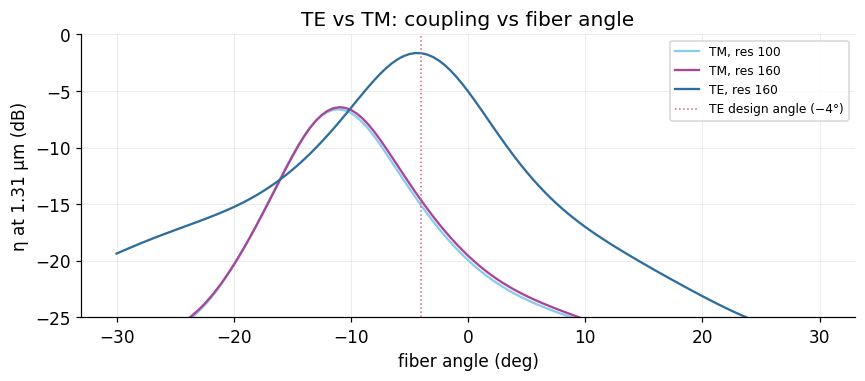

In [7]:
tm = {res: sg.cached(DATA / f"uniform_TM_res{res}.pkl", lambda: ag.run_forward({"resolution": res, "pol": "TM"}))
      for res in (100, 160)}
ANG = np.arange(-30, 30.01, 0.5)
fig, ax = plt.subplots(figsize=(8, 3.6))
for (res, r), c in zip(tm.items(), (style.COLOR_CYCLE[1], style.COLOR_CYCLE[5])):
    s_tm = ag.summary(r)
    e = np.array([ag.best(r, angle_deg=a)[1] for a in ANG])
    k = int(np.argmax(e))
    ax.plot(ANG, 10 * np.log10(e), color=c, label=f"TM, res {res}")
    print(f"TM res {res}: at -4 deg {s_tm['eta_db']:.2f} dB; best {ANG[k]:+.1f} deg -> {10 * np.log10(e[k]):.2f} dB; "
          f"up {s_tm['up']:.3f}, down {s_tm['down']:.3f}, directionality {s_tm['directionality']:.2f}, T {s_tm['T']:.3f}")
e_te = np.array([ag.best(r160, angle_deg=a)[1] for a in ANG])
ax.plot(ANG, 10 * np.log10(e_te), color=style.COLOR_STEEL, label="TE, res 160")
ax.axvline(-4, color=style.COLOR_ROSE, lw=1, ls=":", label="TE design angle (−4°)")
ax.set(xlabel="fiber angle (deg)", ylabel="η at 1.31 µm (dB)", ylim=(-25, 0), title="TE vs TM: coupling vs fiber angle")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 7. Summary

- **The overlay solves the problem the in-plane meta-atoms could not.** The a-Si overlay
  grating reaches −1.66 dB (res 160; numerical spread 0.3 dB over res 100–160) with a
  directionality of 0.93, against −4.14 dB and 0.73 for the optimized single-etch SiN
  grating of Step 2. (The two platforms differ in wavelength and top cladding, so this
  compares mechanisms, not identical devices.)
- **The buffer sets the grating strength, not the directionality** (Section 5).
- **TM:** the same grating serves TM poorly: −14.7 dB at the TE fiber angle and −6.4 dB
  at its own best angle (−11°), with 43 % of the TM power passing the grating and a
  directionality of 0.69. The 400 nm SiN guide's birefringence (n_TE − n_TM = 0.12)
  places the two polarizations at fiber angles about 7° apart. A single a-Si-overlay
  grating serving both polarizations has been demonstrated on 800 nm SiN [2].

**Limits.** 2D, uniform grating. Transverse sub-wavelength (metamaterial) teeth and
focusing grating lines need a 3D model: a y-periodic unit cell for the teeth, a full 3D
run for a focusing device.

## 8. References

1. W. Fraser, D. Benedikovic, R. Korcek, M. Milanizadeh, D.-X. Xu, J. H. Schmid,
   P. Cheben, W. N. Ye, "High-efficiency self-focusing metamaterial grating coupler in
   silicon nitride with amorphous silicon overlay", *Sci. Rep.* **14**, 11651 (2024),
   doi:10.1038/s41598-024-62336-0.
2. M. Kohli et al., "C- and O-band dual-polarization fiber-to-chip grating couplers for
   silicon nitride photonics", *ACS Photonics* **10**, 3366 (2023).